# ML-KEM SampleNTT: capture on Husky + CW308 STM32F4

This is the **hardware lab**. Work downward, reading the explanation before executing each cell with **Shift+Enter**. You will connect your **ChipWhisperer Husky**, build and program your **CW308_STM32F4**, capture real power traces, inspect them, collect a reproducible dataset, then repeat with FLS.

Start with **variable-time SampleNTT**, one polynomial per trigger, known generated seeds. Then compare it with the pinned ProjectTempo **top-level FLS** implementation. The standard-like A0 code has a 280-pair cap; FLS always processes 280 pairs. The implementation differences are documented in the companion lab.

The cells below perform real device operations when you run them. There is no mock backend in this notebook. The earlier software-only walkthrough is preserved as `ML-KEM SampleNTT - Software Validation.ipynb` in the companion folder.

Reference: [Tempo](https://doi.org/10.46586/tches.v2026.i3.744-768), [ProjectTempo](https://github.com/afonsoarriaga/ProjectTempo), [FIPS 203 Algorithm 7](https://nvlpubs.nist.gov/nistpubs/FIPS/NIST.FIPS.203.pdf).

## 1. Prepare the kernel and wiring

Use the Python environment in which your other ChipWhisperer hardware labs work. From a terminal, install the companion dependencies if needed:

```bash
cd "$HOME/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab"
python -m pip install -r requirements.txt
python -m pip install -e "$HOME/Desktop/work/chipwhisperer-new"
```

On Arch, the build uses `arm-none-eabi-gcc`, `arm-none-eabi-newlib`, and `make`. The notebook prints the Python executable so you can check the selected kernel.

Connect Husky's 20-pin target header to the CW308 and connect the target's power-measurement SMA output to Husky's analog input. Use the CW308 target's usual power/shunt and external-clock configuration from your working STM32F4 labs. This notebook drives the target clock on **HS2**, uses **TIO1/TIO2** for SimpleSerial, and uses **TIO4** for the trigger. Close connections held by other notebook kernels before connecting here.

In [1]:
from pathlib import Path
import sys, time, json, hashlib
from dataclasses import asdict
from datetime import datetime, timezone
from uuid import uuid4

here = Path.cwd().resolve()
roots = [here, *list(here.parents)[:5]]
candidates = [p / 'custom/mlkem-samplentt-power-lab' for p in roots]
candidates += [p / 'courses/custom/mlkem-samplentt-power-lab' for p in roots]
candidates += [p / 'jupyter/courses/custom/mlkem-samplentt-power-lab' for p in roots]
candidates += [p / 'mlkem-samplentt-power-lab' for p in roots]
if (here / 'analysis/ground_truth.py').is_file():
    candidates.insert(0, here)
LAB = next((p for p in candidates if (p / 'analysis/ground_truth.py').is_file()), None)
if LAB is None:
    raise FileNotFoundError('Set LAB to the companion folder under jupyter/courses/custom.')
sys.path.insert(0, str(LAB))
# Resolve the checkout containing LAB, even when the kernel starts elsewhere.
CW_ROOT = next((p for p in LAB.parents if (p / 'firmware/mcu/Makefile.inc').is_file()),
               Path.home() / 'Desktop/work/chipwhisperer-new')

import numpy as np
import matplotlib.pyplot as plt
import chipwhisperer as cw
from IPython.display import display, Markdown
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(items, **kwargs):
        for i, item in enumerate(items):
            print(f"Capture {i+1}", end='\r')
            yield item
from analysis.ground_truth import ground_truth, generated_seed, output_digest
from analysis.c_reference import verify_sources
from analysis.hardware import seed_roi, classify_roi
from capture.records import acquire_batch, save_dataset, load_dataset
from capture.hardware import HardwareBackend, HardwareSettings
from firmware.build import build

print('Python:', sys.executable)
print('ChipWhisperer:', cw.__version__)
print('Repository:', CW_ROOT)
print('Companion lab:', LAB)
print('Pinned sampler revision:', verify_sources()['commit'])
RUN = LAB / 'results/runs' / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + uuid4().hex[:8])
RUN.mkdir(parents=True)
datasets, dataset_paths, scores = {}, {}, {}
print('Results for this session:', RUN)

Python: /home/ubuntu/Desktop/work/chipwhisperer-new/.venv/bin/python
ChipWhisperer: 7.0.0
Repository: /home/ubuntu/Desktop/work/chipwhisperer-new
Companion lab: /home/ubuntu/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab
Pinned sampler revision: fd72834bd789c644b52fe0d62b2fa3b9f34dfaec
Results for this session: /home/ubuntu/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab/results/runs/20261028T202628Z-99b0d057


## 2. Select your hardware and the first implementation

These settings match the hardware you confirmed. Leave `SCOPE_SN=None` if only your Husky is connected; supply its serial number if more than one capture device is attached. SimpleSerial **1.1** must match the adapter build.

The target frequency is the usual **7.3728 MHz** used by your ChipWhisperer STM32F4 setup. At this clock, the adapter uses **38400 baud**. Keep this preset for the first run. Changing the target frequency also requires matching the firmware build clock configuration and UART baud.

In [2]:
PLATFORM = 'CW308_STM32F4'
CAPTURE_DEVICE = 'Husky'
SCOPE_SN = None
SS_VER = 'SS_VER_1_1'
TARGET_FREQ = 7_372_800
UART_BAUD = 38_400
VARIANT = 'variable_time'
OPTIMIZATION = '2'
X_INDEX, Y_INDEX = 0, 0
assert PLATFORM == 'CW308_STM32F4' and CAPTURE_DEVICE == 'Husky'
print(f'{CAPTURE_DEVICE} → {PLATFORM}; {VARIANT}; SimpleSerial 1.1')

Husky → CW308_STM32F4; variable_time; SimpleSerial 1.1


## 3. Connect the scope and target

This is the same connection pattern as the hardware course labs. The `scope` and `target` variables remain available for you to inspect or adjust. The default setup enables the normal capture path; subsequent cells set the exact clocks, trigger and ADC window.

If this cell reports that the device is busy, run the disconnect cell at the bottom of the notebook that currently owns the Husky, or restart that other kernel.

In [3]:
scope = cw.scope(sn=SCOPE_SN)
if 'husky' not in str(scope).lower():
    scope.dis()
    raise RuntimeError('This notebook is configured for Husky; connected device differs.')
scope.default_setup()
scope.clock.clkgen_freq = TARGET_FREQ
scope.clock.adc_mul = 4
scope.io.hs2 = 'clkgen'
scope.io.tio1 = 'serial_rx'
scope.io.tio2 = 'serial_tx'
scope.io.tio3 = 'high_z'
scope.trigger.module = 'basic'
scope.trigger.triggers = 'tio4'
target = cw.target(scope, cw.targets.SimpleSerial)
target.baud = UART_BAUD
time.sleep(0.25)
assert scope.clock.adc_locked, 'ADC clock did not lock; inspect the clock settings.'
print(scope)

scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 137209                    to 5000                     
scope.adc.trig_count                     changed from 756523471                 to 781828896                
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx                
scope.io.hs2       

## 4. Build the variable-time firmware

This builds only the single-polynomial adapter and its pinned upstream sampler/SHAKE dependencies. It does not build NoIC or the full ML-KEM protocol.

The build produces `.hex`, `.elf`, `.asm`, `build.log`, and `build.json` under `firmware/variable_time/`. The metadata records the compiler commands, optimization, source revision and image hashes. A failed build reports the log path; inspect that log before proceeding.

In [9]:
build_record = build(CW_ROOT, PLATFORM, VARIANT, optimization=OPTIMIZATION)
BUILD_JSON = LAB / 'firmware' / VARIANT / 'build.json'
FIRMWARE_HEX = Path(build_record['image'])
print('Image:', FIRMWARE_HEX)
print('Compiler:', build_record['compiler'])
print('Image SHA-256:', build_record['firmware_sha256'])

Image: /home/ubuntu/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab/firmware/variable_time/samplentt-variable_time-CW308_STM32F4.hex
Compiler: arm-none-eabi-gcc (15:14.2.rel1-1) 14.2.1 20241119
Image SHA-256: fbe72dbef701cfd52eb08b3ca895c66112c9296e3d89797c0ff2301b318f91f3


## 5. Program and reset the STM32F4

Running the next cell **replaces the firmware on your CW308 STM32F4 target** with the sampler adapter you just built. It uses `STM32FProgrammer`, as in your STM32F4 course notebooks. Allow programming to complete before continuing.

In [10]:
cw.program_target(scope, cw.programmers.STM32FProgrammer, str(FIRMWARE_HEX))

def reset_target():
    scope.io.nrst = 'low'
    time.sleep(0.05)
    scope.io.nrst = 'high_z'
    time.sleep(0.25)
    target.flush()

reset_target()
print('Variable-time firmware programmed and target reset.')

Detected known STMF32: STM32F40xxx/41xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 15203 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 15203 bytes
Variable-time firmware programmed and target reset.


In [11]:
import importlib
import capture.hardware as hw
importlib.reload(hw)
HardwareBackend, HardwareSettings = hw.HardwareBackend, hw.HardwareSettings

## 6. Set the capture window

Start with a **24,000-sample window** at four ADC samples per target clock. It may cover only part of the operation. We will measure the complete trigger duration separately, so a short trace is not mistaken for a short execution.

Adjust `GAIN_DB`, `OFFSET`, and `SAMPLES`, then rerun this cell and the attach/capture cells below. `OFFSET` is measured in ADC samples from the rising trigger. It lets you inspect later parts without modifying the sampler.

For a one-trace survey of a long FLS operation, you can instead set `ADC_MUL=1`, `STREAM_MODE=True`, and a larger `SAMPLES`, such as `4_000_000`. This gives 7.3728 MS/s, below the approximate 10 MS/s streaming rate described by this checkout. Increase the count if it still does not cover the trigger. Streaming records a fixed number of samples; it does not stop automatically when the operation ends. Return to a useful short window for batches to keep datasets manageable, and use matching settings for comparisons.

Start at **10 dB** gain and tune on the actual waveform. If Husky reports `ADC clipped`, reduce the gain, clear the error flags, and rerun the attach and capture cells. The polynomial check may pass even when the power trace is saturated.


In [6]:
ADC_MUL = 4
STREAM_MODE = False
SAMPLES = 24_000
OFFSET = 0
GAIN_DB = 10
CAPTURE_TIMEOUT = 10.0

if STREAM_MODE and TARGET_FREQ * ADC_MUL > 10_000_000:
    raise ValueError('Use ADC_MUL=1 for the initial streaming survey.')
scope.clock.adc_mul = ADC_MUL
scope.adc.presamples = 0
scope.adc.segments = 1
scope.adc.decimate = 1
scope.adc.stream_mode = STREAM_MODE
scope.adc.samples = SAMPLES
scope.adc.offset = OFFSET
scope.adc.basic_mode = 'rising_edge'
scope.adc.timeout = CAPTURE_TIMEOUT
scope.gain.db = GAIN_DB
scope.adc.errors = 0
time.sleep(0.25)
assert scope.clock.adc_locked
print('ADC:', scope.clock.adc_freq, 'Hz; samples:', scope.adc.samples,
      '; offset:', scope.adc.offset, '; streaming:', scope.adc.stream_mode)

ADC: 29454545.454545453 Hz; samples: 24000 ; offset: 0 ; streaming: False


## 7. Verify the firmware identity and attach the recorder

The application `i` command checks that the selected sampler variant and upstream revision are running. This helper uses the **same** scope and target you connected and programmed; it does not reopen them.

After changing ADC settings, rerun this cell to snapshot the new settings. Each subsequent trace stores that snapshot, build metadata, seed, indices and ground truth.

`v` is reserved by SimpleSerial and must not be used for application identity. After updating this adapter, rerun **4 (build)** and **5 (program/reset)** before attaching. The cell below reloads the Python helper without closing your current USB connection.


In [13]:
# Reload the recorder after an on-disk fix without restarting the live kernel.
import importlib
import capture.hardware as capture_hardware
capture_hardware = importlib.reload(capture_hardware)
HardwareBackend = capture_hardware.HardwareBackend
HardwareSettings = capture_hardware.HardwareSettings

def attach_recorder(build_path):
    settings = HardwareSettings(
        model='Husky', target_platform=PLATFORM, build_json=str(build_path),
        scope_serial=str(scope.sn), target_clock_hz=TARGET_FREQ,
        adc_multiplier=int(scope.clock.adc_mul), samples=int(scope.adc.samples),
        offset=int(scope.adc.offset), gain_db=float(scope.gain.db),
        baud=int(target.baud), timeout_seconds=float(scope.adc.timeout),
        stream_mode=bool(scope.adc.stream_mode))
    return HardwareBackend.from_connected(scope, target, settings, cw_version=cw.__version__)

recorder = attach_recorder(BUILD_JSON)
print('Verified:', recorder.build['variant'], recorder.build['source_commit'])

Verified: variable_time fd72834bd789c644b52fe0d62b2fa3b9f34dfaec


In [16]:
GAIN_DB = 10
scope.gain.db = GAIN_DB
scope.adc.errors = 0

# Record the updated gain settings:
recorder = attach_recorder(BUILD_JSON)

## 8. Capture one real trace

The recorder performs the usual ChipWhisperer sequence:

1. Arm the ADC with `scope.arm()`.
2. Send `p` with `ρ[32] || x || y`.
3. Wait for `scope.capture()`.
4. Read the target's `r` reply and check the entire polynomial against the independent Python reference.
5. Copy the waveform and read the trigger counter after the target has finished.

The trigger encloses the complete upstream function, including SHAKE128 and its context allocation/release. Initialization, output encoding, verification hashing and UART replies are outside it. The reply is `SHA3-256(LE16(coefficients[256]))`; a mismatch stops that capture.

The matrix entry `A[row,column]` uses **x=column, y=row**. Here we capture one polynomial with a known seed.

Polynomial digest verified: bc176defc05b9225a7855bc1884abd69efe3d6ec9b665b6a1ee5a34064c0fe95
Trigger duration: 13348.160493827161 µs
Full operation in waveform: False
Pair iterations: 158 ; decoded candidates: 316 ; committed coefficients: 256


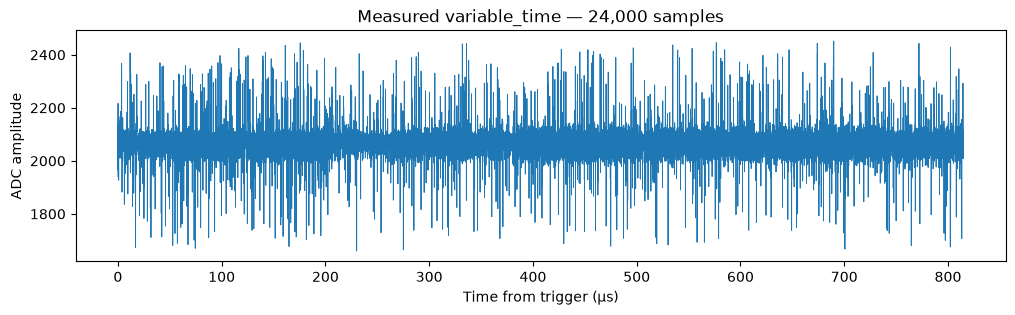

PosixPath('/home/ubuntu/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab/results/runs/20261028T202628Z-99b0d057/first-variable_time-85b562e9')

In [17]:
TEST_SEED = bytes(range(32))
first = recorder.capture(TEST_SEED, X_INDEX, Y_INDEX, VARIANT)
print('Polynomial digest verified:', first.metadata['verification_digest'])
print('Trigger duration:', first.metadata['duration_seconds'] * 1e6, 'µs')
print('Full operation in waveform:', first.metadata['full_operation_captured'])
print('Pair iterations:', first.truth['pair_iterations'],
      '; decoded candidates:', len(first.truth['candidates']),
      '; committed coefficients:', sum(first.truth['committed']))


def show_trace(record, start=0, stop=None):
    stop = len(record.wave) if stop is None else min(stop, len(record.wave))
    if not 0 <= start < stop:
        raise ValueError('Choose a nonempty range inside the trace.')
    x = (record.metadata['sample_window_start'] + np.arange(start, stop)) / record.metadata['adc_frequency_hz'] * 1e6
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(x, record.wave[start:stop], lw=0.65)
    ax.set(xlabel='Time from trigger (µs)', ylabel='ADC counts',
           title=f"Measured {record.truth['variant']} — {stop-start:,} samples")
    plt.show()
    return fig

show_trace(first)
save_dataset(RUN / ('first-' + VARIANT + '-' + uuid4().hex[:8]), [first], [], asdict(recorder.settings))

### 8a. Diagnose a rejected ADC capture

If the capture above fails with `ADC clipped`, run this cell to inspect the last raw buffer without needing `first`. The buffer is for diagnosis and is not saved as accepted research data.

Reduce the gain from 25 dB to 10 dB initially; try 0 dB if necessary. After changing gain, run `scope.adc.errors = 0`, recreate `recorder = attach_recorder(BUILD_JSON)` so the recorded settings match, then rerun the capture. Keep clipping detection enabled; clearing a flag alone does not fix saturation.

The recorder saves raw ADC counts under ChipWhisperer 7. This diagnostic explicitly requests `as_int=False`, so its clipping limits are on the normalized scale. Rerun the cell to refresh its existing plot; the saved capture files are unchanged.


Current gain: 9.770642201834864 dB
ADC error flags: False


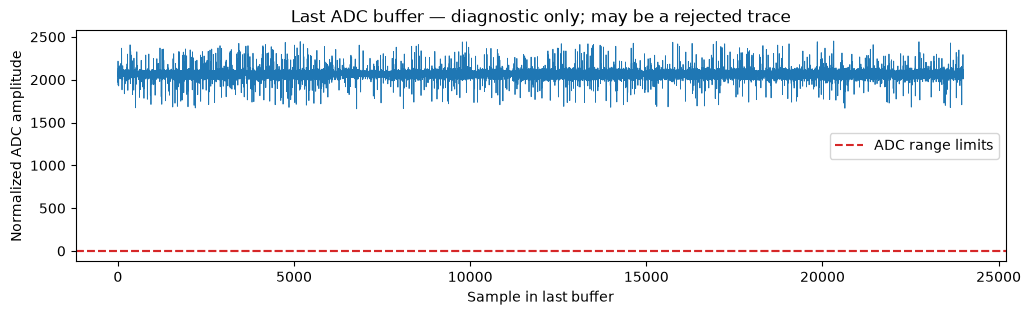

Buffer min/max: 1660.0 2452.0
Changing gain does not change this old buffer; acquire a fresh trace afterward.


In [18]:
# Inspect the last buffer even if recorder.capture() rejected the trace.
last_adc = scope.get_last_trace(as_int=False)
print('Current gain:', scope.gain.db, 'dB')
print('ADC error flags:', scope.adc.errors)
if last_adc is None or len(last_adc) == 0:
    print('No ADC buffer yet. Attempt one capture first.')
else:
    diagnostic_wave = np.asarray(last_adc, dtype=float)
    adc_low = -0.5
    adc_high = 0.5 - 2.0 ** (-int(scope.adc.bits_per_sample))
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(diagnostic_wave, lw=0.6)
    ax.axhline(adc_low, color='tab:red', ls='--', label='ADC range limits')
    ax.axhline(adc_high, color='tab:red', ls='--')
    ax.set(xlabel='Sample in last buffer', ylabel='Normalized ADC amplitude',
           title='Last ADC buffer — diagnostic only; may be a rejected trace')
    ax.legend()
    plt.show()
    print('Buffer min/max:', float(diagnostic_wave.min()), float(diagnostic_wave.max()))
    print('Changing gain does not change this old buffer; acquire a fresh trace afterward.')


## 9. Inspect a zoomed region and tune the setup

Change the two sample indices below to inspect the waveform. To acquire a different time window, change `OFFSET` in section 6, rerun sections 6–8, and inspect again. Keep the same seed while tuning so input differences do not obscure changes to the capture setup.

If capture raises `ADC clipped`, lower the gain; if the ADC reports a low-gain error, increase it after inspecting the signal. Missing triggers point to the target clock, reset, firmware, TIO4 or wiring. A missing/incorrect reply points to programming, baud, clock or input encoding. A partial waveform is allowed and labeled; `len(wave)` alone does not tell you the operation length.

Each saved acquisition receives a unique directory, so you can rerun the single-trace and batch cells while tuning. Previously saved trials remain available.

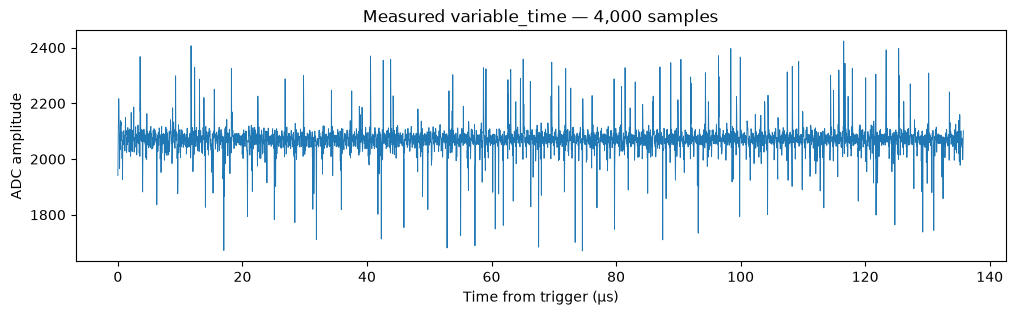

ADC error flags: False


In [19]:
ZOOM_START, ZOOM_STOP = 0, 4_000
show_trace(first, ZOOM_START, ZOOM_STOP)
print('ADC error flags:', scope.adc.errors)

## 10. Capture a batch of generated seeds

Once one trace verifies and the waveform looks useful, capture a small batch. The acquisition order is randomized. Repetitions of the same seed let you compare single measurements with averaging; they are not extra independent seeds for the classifier.

The progress bar updates as traces arrive. Timeouts, ADC errors and digest failures are recorded with their input identity, and their traces are excluded. Interrupting a capture returns and saves the completed portion of the batch; reset the target before starting again. Stop and fix the setup if failures are frequent. The default 64 seeds × 2 repetitions is a starting dataset, not a sample-size justification for a final leakage claim.

In [20]:
N_SEEDS, REPEATS = 64, 2
SEED_DOMAIN = 'hardware-lab-v1'
seeds = [generated_seed(i, SEED_DOMAIN) for i in range(N_SEEDS)]
records, failures = acquire_batch(
    recorder, seeds, VARIANT, repeats=REPEATS, x=X_INDEX, y=Y_INDEX,
    order_seed=42, keep_partial_on_interrupt=True, progress=lambda items: tqdm(items, desc=f'Capturing {VARIANT}', total=N_SEEDS*REPEATS))
datasets[VARIANT] = records
destination = RUN / (VARIANT + '-' + uuid4().hex[:8])
dataset_paths[VARIANT] = save_dataset(destination, records, failures, {
    'hardware': asdict(recorder.settings), 'n_seeds': N_SEEDS,
    'repeats': REPEATS, 'seed_domain': SEED_DOMAIN})
print('Saved:', dataset_paths[VARIANT])
print('Successful:', len(records), 'Failed:', len(failures))
if failures:
    display(failures[:5])
if not records:
    raise RuntimeError('No valid captures. Resolve the reported failures before analysis.')

Capturing variable_time:   0%|          | 0/128 [00:00<?, ?it/s]

Saved: /home/ubuntu/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab/results/runs/20261028T202628Z-99b0d057/variable_time-832b851b
Successful: 128 Failed: 0


## 11. Inspect measured waveforms and timing

First compare a few waveforms and plot the duration against the reference pair count. Timing is derived from the ADC trigger counter, read after the target reply when TIO4 is low. Its raw unit is ADC clock cycles; seconds use the measured ADC frequency. Host UART/USB round-trip latency is not the operation duration.

`full_operation_captured=False` means power analysis uses a window, while the trigger still measured the complete call. The trigger encloses SHAKE and sampling, so pair count alone is not a full timing model.

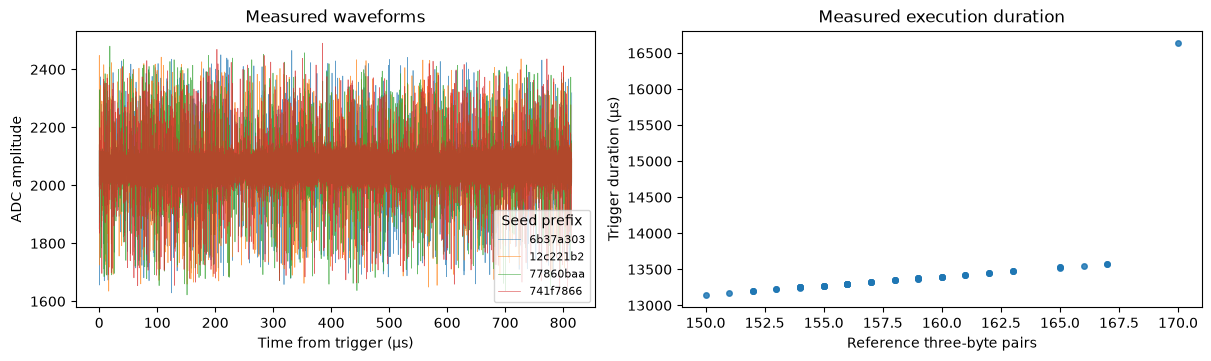

Duration: mean 13394.565 µs; SD 422.102 µs
Complete power windows: 0 / 128


In [21]:
def inspect_batch(records):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
    for record in records[:4]:
        x = (record.metadata['sample_window_start'] + np.arange(len(record.wave))) / record.metadata['adc_frequency_hz'] * 1e6
        axes[0].plot(x, record.wave, lw=0.5, alpha=0.7, label=record.truth['seed'][:8])
    axes[0].set(xlabel='Time from trigger (µs)', ylabel='ADC counts', title='Measured waveforms')
    axes[0].legend(title='Seed prefix', fontsize=8)
    duration = np.array([r.metadata['duration_seconds'] for r in records]) * 1e6
    pairs = np.array([r.truth['pair_iterations'] for r in records])
    axes[1].scatter(pairs, duration, s=15, alpha=0.6)
    axes[1].set(xlabel='Reference three-byte pairs', ylabel='Trigger duration (µs)', title='Measured execution duration')
    plt.show()
    print(f'Duration: mean {duration.mean():.3f} µs; SD {duration.std(ddof=1):.3f} µs')
    print('Complete power windows:', sum(r.metadata['full_operation_captured'] for r in records), '/', len(records))
    return fig

fig = inspect_batch(datasets[VARIANT])
fig.savefig(RUN / (VARIANT + '-waveforms-and-timing.png'), dpi=150)

## 12. Test an explicit power region against candidate validity

Select a region **inside the acquired window**, in sample indices. The initial region below is an inspection region, not a claimed location of candidate 0. Locate a physically motivated region using the waveform and disassembly, or separately labeled debug firmware, before treating it as an acceptance-operation measurement. No synthetic segment boundaries are applied to hardware.

For this exploratory hypothesis, the label is whether candidate `CANDIDATE_INDEX` is below 3329. Validity differs from committing an output coefficient, especially after the FLS output fills. Each seed's repeats are averaged, then seeds are split into training and test sets. Features are means of 32 equal time bins; scaling and logistic regression are fitted on training data only.

Freeze the region and hypothesis before inspecting held-out scores for a formal experiment. Repeatedly changing a window in response to test accuracy invalidates that holdout. The majority-class balanced-accuracy baseline is **0.5**. Results near chance are a valid outcome, and a correlation does not by itself localize the comparison or identify the seed.

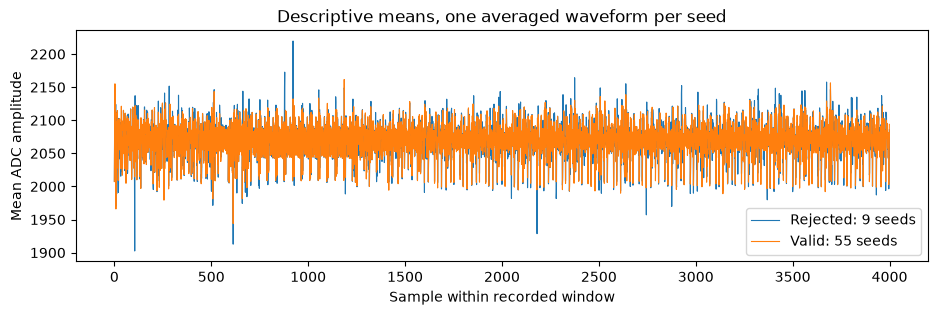

Train/test seeds: 44 / 20
Balanced accuracy: 0.52 ; baseline: 0.5
Precision/recall (valid): 0.857 / 0.706
ROC-AUC: 0.608
Confusion matrix [rejected, valid], rows=true, columns=predicted:
[[ 1  2]
 [ 5 12]]


In [22]:
ROI_START, ROI_STOP = 0, min(4_000, int(scope.adc.samples))
CANDIDATE_INDEX = 0
FEATURE_BINS = 32
SPLIT_SEED = 123


def evaluate_region(records, start, stop):
    X, labels, seed_ids, waveforms = seed_roi(records, start, stop, CANDIDATE_INDEX, FEATURE_BINS)
    result = classify_roi(records, start, stop, CANDIDATE_INDEX, FEATURE_BINS, SPLIT_SEED)
    fig, ax = plt.subplots(figsize=(11, 3))
    for label, name in [(0, 'Rejected'), (1, 'Valid')]:
        group = waveforms[labels == label]
        if len(group):
            ax.plot(np.arange(start, stop), group.mean(axis=0), label=f'{name}: {len(group)} seeds', lw=0.8)
    ax.set(xlabel='Sample within recorded window', ylabel='Mean ADC counts', title='Descriptive means, one averaged waveform per seed')
    ax.legend(); plt.show()
    print('Train/test seeds:', len(result['train_seeds']), '/', len(result['test_seeds']))
    print('Balanced accuracy:', round(result['balanced_accuracy'], 3), '; baseline:', result['majority_balanced_accuracy'])
    print('Precision/recall (valid):', round(result['precision_valid'], 3), '/', round(result['recall_valid'], 3))
    print('ROC-AUC:', round(result['roc_auc'], 3))
    print('Confusion matrix [rejected, valid], rows=true, columns=predicted:')
    print(np.array(result['confusion_matrix_reject_valid']))
    return result, fig

scores[VARIANT], fig = evaluate_region(datasets[VARIANT], ROI_START, ROI_STOP)
(RUN / (VARIANT + '-roi-metrics.json')).write_text(json.dumps(scores[VARIANT], indent=2) + '\n')
fig.savefig(RUN / (VARIANT + '-roi-means.png'), dpi=150)

## 13. Replace the target firmware with FLS

The variable-time dataset is already saved. The next two cells build and **program FLS** on the same STM32F4. They keep the current acquisition settings. Reusing a capture configuration makes the measurement comparison clearer; it does not imply the same ROI corresponds to the same internal operation.

The selected top-level FLS code makes two 256-word scans per pair, including after the output fills. It can run much longer than A0. Its SHAKE and allocator calls are also inside the trigger. The build's `.asm` file lets you inspect the actual compiled loops; fixed-loop source is not a complete machine-code timing audit.

In [ ]:
VARIANT = 'fls'
build_record = build(CW_ROOT, PLATFORM, VARIANT, optimization=OPTIMIZATION)
BUILD_JSON = LAB / 'firmware' / VARIANT / 'build.json'
FIRMWARE_HEX = Path(build_record['image'])
print('FLS image:', FIRMWARE_HEX)
print('Assembly:', FIRMWARE_HEX.with_suffix('.asm'))

In [ ]:
cw.program_target(scope, cw.programmers.STM32FProgrammer, str(FIRMWARE_HEX))
reset_target()
recorder = attach_recorder(BUILD_JSON)
print('Verified running firmware:', recorder.build['variant'])

## 14. Capture FLS once and verify the output

Use the same seed and indices as the first A0 capture. The expected polynomial is the same when the bounded schedule fills, but FLS continues all 560 candidate comparisons. Candidate validity after filling is still recorded; it does not mean the output is updated.

If the power window is short, inspect the measured trigger duration before choosing a later offset or a streaming survey. The response timeout must allow the whole FLS call to finish even when the ADC captured only an early window.

In [ ]:
fls_first = recorder.capture(TEST_SEED, X_INDEX, Y_INDEX, VARIANT)
assert fls_first.truth['coefficients'] == first.truth['coefficients']
assert fls_first.metadata['verification_digest'] == first.metadata['verification_digest']
print('Same polynomial verified for A0 and FLS.')
print('FLS trigger duration:', fls_first.metadata['duration_seconds'] * 1e6, 'µs')
print('Full operation in waveform:', fls_first.metadata['full_operation_captured'])
print('Comparisons:', len(fls_first.truth['candidates']), '; committed coefficients:', sum(fls_first.truth['committed']))
show_trace(fls_first)
save_dataset(RUN / ('first-fls-' + uuid4().hex[:8]), [fls_first], [], asdict(recorder.settings))

## 15. Capture the same generated seeds with FLS

This uses the same seed list and repetition count as A0, in a randomized order. It does not reuse an A0-trained classifier. If you changed the ADC settings after A0, either recollect A0 with matching settings or treat the two datasets as separate measurement conditions.

In [ ]:
fls_records, fls_failures = acquire_batch(
    recorder, seeds, VARIANT, repeats=REPEATS, x=X_INDEX, y=Y_INDEX,
    order_seed=43, keep_partial_on_interrupt=True, progress=lambda items: tqdm(items, desc='Capturing FLS', total=N_SEEDS*REPEATS))
datasets['fls'] = fls_records
dataset_paths['fls'] = save_dataset(RUN / ('fls-' + uuid4().hex[:8]), fls_records, fls_failures, {
    'hardware': asdict(recorder.settings), 'n_seeds': N_SEEDS,
    'repeats': REPEATS, 'seed_domain': SEED_DOMAIN})
print('Saved:', dataset_paths['fls'])
print('Successful:', len(fls_records), 'Failed:', len(fls_failures))
if fls_failures:
    display(fls_failures[:5])
if not fls_records:
    raise RuntimeError('No valid FLS captures; resolve the reported failures.')
fig = inspect_batch(fls_records)
fig.savefig(RUN / 'fls-waveforms-and-timing.png', dpi=150)

## 16. Evaluate an FLS region independently

FLS has a different instruction layout. Choose `FLS_ROI_START/STOP` independently; do not assume the A0 region maps to the same comparison. The split again keeps seeds disjoint, and a new model is fitted for FLS. Use single-repeat subsets if you want to compare averaging against single measurements.

In [ ]:
FLS_ROI_START, FLS_ROI_STOP = 0, min(4_000, int(scope.adc.samples))
scores['fls'], fig = evaluate_region(datasets['fls'], FLS_ROI_START, FLS_ROI_STOP)
(RUN / 'fls-roi-metrics.json').write_text(json.dumps(scores['fls'], indent=2) + '\n')
fig.savefig(RUN / 'fls-roi-means.png', dpi=150)

## 17. Compare measured timing and power results

The table summarizes this session. Timing variation is measured, not assumed constant. The power score is an acceptance-label experiment for the selected ROI; it is not a known-seed identification rate or a password-recovery result.

Check the conditions as well as the scores. Differences in ADC frequency, gain, offset or window length can change the apparent result. This table is descriptive, and repeated captures remain grouped by seed in classification.

In [ ]:
def condition(record):
    s = record.metadata['settings']
    return (record.metadata['adc_frequency_hz'], s['gain_db'], s['offset'], s['samples'], s['stream_mode'])

same_conditions = condition(datasets['variable_time'][0]) == condition(datasets['fls'][0])
print('Matching ADC frequency/gain/offset/window/streaming:', same_conditions)
rows = ['| Implementation | Captures | Duration mean (µs) | Duration SD (µs) | ROI balanced accuracy | ROI ROC-AUC |',
        '|---|---:|---:|---:|---:|---:|']
fig, ax = plt.subplots(figsize=(9, 3))
for variant in ('variable_time', 'fls'):
    data = datasets[variant]
    times = np.array([r.metadata['duration_seconds'] for r in data]) * 1e6
    score = scores[variant]
    rows.append(f"| {variant} | {len(data)} | {times.mean():.3f} | {times.std(ddof=1):.3f} | {score['balanced_accuracy']:.3f} | {score['roc_auc']:.3f} |")
    ax.hist(times, bins=20, alpha=0.6, label=variant)
ax.set(xlabel='Measured trigger duration (µs)', ylabel='Captures', title='Measured duration distributions')
ax.legend(); plt.show()
display(Markdown('\n'.join(rows)))
fig.savefig(RUN / 'timing-comparison.png', dpi=150)
(RUN / 'comparison.json').write_text(json.dumps({'same_capture_conditions': same_conditions,
    'datasets': {k: str(v) for k, v in dataset_paths.items()}, 'roi_results': scores}, indent=2) + '\n')
print('Session results:', RUN)

## 18. Reload data without recapturing

Your saved datasets contain numeric NPZ waveforms and JSON metadata/ground truth. After reconnecting or restarting a kernel, you can reload them for analysis without rebuilding or flashing. Replace the path below with a dataset directory printed during your session.

In [ ]:
# Example using the current session's saved variable-time dataset:
reloaded_records, reloaded_manifest = load_dataset(dataset_paths['variable_time'])
print('Reloaded:', len(reloaded_records), 'verified captures')
print('Saved environment:', reloaded_manifest['environment'])

## 19. Disconnect

Run this when finished, before opening the hardware in another notebook. Saved data remains available.

A successful capture workflow establishes that this setup can acquire and verify the operation. A power-leakage conclusion still needs controlled measurements, noise/alignment analysis and a defensible choice of hypothesis/window. Distinguish leakage detection from known-seed distinction and from protocol-level consequences. A negative result on this board/compiler/window is not a general side-channel security proof.

The companion `docs/reference-inspection.md` documents the top-level/pqm4 FLS differences. `ML-KEM SampleNTT - Software Validation.ipynb` provides the optional mock and C/Python reference checks. Original lab code: GPL-3.0-or-later; vendor notices are retained. ChipWhisperer course context: [ChipWhisperer.io](https://www.chipwhisperer.io/).

In [ ]:
try:
    target.dis()
finally:
    scope.dis()
print('Disconnected. Saved results:', RUN)